# Policies and traffic lights: thresholds are policy, never regulation

- **Level:** 1, Fundamentals
- **Prerequisites:** notebook 02 of this topic (a first TestResult)
- **Reading time:** about 25 minutes

## Objectives

By the end of this notebook you can:

- read the engine's default `Policy` and say what each kind of threshold means;
- classify a p-value or a metric into a light by hand and with `Policy.classify`;
- build a stricter and a more lenient policy and show that the statistic and the p-value stay the same while the colour changes;
- explain why Contraste words every light as a reading under a named policy, and never as a regulatory verdict.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.0 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import csv
import importlib.metadata as md
import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
matplotlib 3.11.2


## Data

Two scored samples with a **known truth**, committed in `data/examples/` as the examples of the bring-your-own-model guide (`docs/guides/02_validate-your-own-model.md`). Both are synthetic: the pipeline generates them from a seed (`data-pipeline/pipeline/io/examples.py`), so no third-party dataset and no dataset licence applies, and the repository's MIT licence covers them.

- `scored_sample_development.csv`: 2,000 obligors observed on 2024-12-31 whose PDs are calibrated by construction: each default is a Bernoulli draw at its own PD.
- `scored_sample_current.csv`: 2,000 obligors observed on 2025-12-31 from a riskier population, whose defaults arrive at 1.5 times the PD. The ranking is intact and the level is under-estimated by a third.
- Columns: `id,observation_date,target,pd,segment`, where `target` is 1 for a default over the horizon.

Knowing the truth lets us ask a fair question of a policy: does it find the sample that is wrong and leave the right one alone? The next cell reads both files with the standard library (notebook 04 reads them through contract 1) and prints their level.

In [2]:
# Read the two samples and compare the defaults with the defaults the PDs expect
ROOT = Path("../../..").resolve()
EXAMPLES = ROOT / "data" / "examples"


def read_sample(name):
    with open(EXAMPLES / f"scored_sample_{name}.csv", newline="", encoding="utf-8") as handle:
        rows = list(csv.DictReader(handle))
    return np.array([int(r["target"]) for r in rows]), np.array([float(r["pd"]) for r in rows])


samples = {name: read_sample(name) for name in ("development", "current")}
for name, (y, pd_hat) in samples.items():
    print(f"{name:12s} obligors: {len(y)} | defaults: {int(y.sum())} | defaults expected by the PDs: {pd_hat.sum():.1f} | mean PD: {pd_hat.mean():.4f}")

development  obligors: 2000 | defaults: 100 | defaults expected by the PDs: 111.2 | mean PD: 0.0556
current      obligors: 2000 | defaults: 207 | defaults expected by the PDs: 138.1 | mean PD: 0.0691


## Method

### Step 1: what a policy is

A `Policy` is a named, versioned table of thresholds keyed by test identifier. The credit tests this topic calls hold no threshold: they compute a statistic and a p-value, and the policy turns it into a light. (A few tests of other topics are the exception, because the regulation they implement defines its own zones; see the end of this notebook.) There are three kinds of `Threshold`:

- `p_value`: red if the p-value is below `red`, amber if it is below `amber`, green otherwise;
- `upper_bad` (larger is worse, like the PSI): red at or above `red`, amber at or above `amber`;
- `lower_bad` (smaller is worse, like an AUC): red at or below `red`, amber at or below `amber`.

The next cell opens the packaged default policy and reads its description, the kinds it uses and the thresholds of the tests this topic calls.

In [3]:
# Open the default policy: its label, description, kinds of threshold and a few thresholds
policy = rv.default_policy()
print("label:", policy.label)
print("description:", policy.description)
print("thresholds by kind:", dict(Counter(t.kind for t in policy.thresholds.values())))
for test_id in ("pd.jeffreys", "pd.binomial", "stability.psi", "disc.auc_vs_initial", "disc.auc"):
    print(f"{test_id:22s}", policy.threshold(test_id))

label: riskvalidation-default 2026.10.1
description: Conventional thresholds for illustration and comparison. They are policy choices, not regulatory thresholds: the ECB 2019 IRB validation-reporting instructions set no pass or fail thresholds, and each entry names where its convention comes from. Institutions replace this file with their own policy.
thresholds by kind: {'p_value': 25, 'upper_bad': 20, 'lower_bad': 3}
pd.jeffreys            Threshold(kind='p_value', amber=0.05, red=0.01, source='convention: 5% and 1% significance levels; the ECB (2019) instructions and BCBS WP14 set no thresholds')
pd.binomial            Threshold(kind='p_value', amber=0.05, red=0.01, source='convention: 5% and 1% significance levels; the ECB (2019) instructions and BCBS WP14 set no thresholds')
stability.psi          Threshold(kind='p_value', amber=0.05, red=0.01, source='Yurdakul and Naranjo (2020) chi-square benchmark at 5% and 1%; the 0.10/0.25 bands are reported beside it as a rule of thumb withou

The description is the first thing to read: the thresholds are conventions "for illustration and comparison", and the ECB's 2019 instructions set no pass or fail thresholds. `disc.auc` has no threshold at all, so a result for it can never be coloured: its light is `not_evaluated`.

### Step 2: classify by hand

`Threshold.classify` is the whole rule, and `Policy.classify` looks the threshold up by test identifier and applies it. The next cell classifies three p-values for the Jeffreys test, then a PSI-like value with an `upper_bad` threshold and an AUC-like value with a `lower_bad` one. The two thresholds in the second part are made up for the illustration.

In [4]:
# Classify three p-values with the policy, then two values with illustrative thresholds of the other kinds
for p_value in (0.20, 0.03, 0.004):
    light, threshold = policy.classify("pd.jeffreys", p_value=p_value)
    print(f"pd.jeffreys p={p_value:<6} -> {light.value:6s} (amber below {threshold.amber}, red below {threshold.red})")

upper = rv.Threshold(kind="upper_bad", amber=0.10, red=0.25)
lower = rv.Threshold(kind="lower_bad", amber=0.60, red=0.50)
print("upper_bad, value 0.12 ->", upper.classify(0.12).value)
print("lower_bad, value 0.55 ->", lower.classify(0.55).value)
print("no value ->", upper.classify(None).value)

pd.jeffreys p=0.2    -> green  (amber below 0.05, red below 0.01)
pd.jeffreys p=0.03   -> amber  (amber below 0.05, red below 0.01)
pd.jeffreys p=0.004  -> red    (amber below 0.05, red below 0.01)
upper_bad, value 0.12 -> amber
lower_bad, value 0.55 -> amber
no value -> not_evaluated


### Step 3: one test, two samples, the default policy

Now the engine. `pd_jeffreys` takes the number of obligors, the number of defaults and the applied PD (here the sample's mean PD), and applies the policy it is given. We run it on both samples. The development sample should be left alone and the current one found.

In [5]:
# Run the Jeffreys test on both samples under the default policy
from riskvalidation.validation import pd_jeffreys


def jeffreys_under(policy_in_use, name):
    y, pd_hat = samples[name]
    return pd_jeffreys(n=len(y), d=int(y.sum()), pd=float(pd_hat.mean()), policy=policy_in_use, model_id=name, segment="portfolio")


for name in samples:
    result = jeffreys_under(policy, name)
    print(f"{name:12s} p-value: {result.p_value:.3e} | light: {result.light.value:5s} | policy: {result.policy_version} | amber/red: {result.alpha_amber}/{result.alpha_red}")

development  p-value: 8.629e-01 | light: green | policy: riskvalidation-default 2026.10.1 | amber/red: 0.05/0.01
current      p-value: 6.047e-09 | light: red   | policy: riskvalidation-default 2026.10.1 | amber/red: 0.05/0.01


### Step 4: the same p-value, another policy

A policy is data, so an institution can hold a stricter or a more lenient one. The next cell builds two policies for this one test: `strict-demo` turns amber below 0.90 and red below 0.50, and `lenient-demo` turns amber below 1e-6 and red below 1e-9. Both are illustrations, not recommendations. We then run the same test, on the same arrays, under all three policies.

In [6]:
# Build two policies for one test and read the same p-values under the three of them
strict = rv.Policy(policy_id="strict-demo", version="1", description="illustration: a stricter reading of one test",
                   thresholds={"pd.jeffreys": rv.Threshold(kind="p_value", amber=0.90, red=0.50)})
lenient = rv.Policy(policy_id="lenient-demo", version="1", description="illustration: a more lenient reading of one test",
                    thresholds={"pd.jeffreys": rv.Threshold(kind="p_value", amber=1e-6, red=1e-9)})

for name in samples:
    for in_use in (policy, strict, lenient):
        result = jeffreys_under(in_use, name)
        print(f"{name:12s} {in_use.policy_id:26s} p-value: {result.p_value:.3e} | light: {result.light.value}")

development  riskvalidation-default     p-value: 8.629e-01 | light: green
development  strict-demo                p-value: 8.629e-01 | light: amber
development  lenient-demo               p-value: 8.629e-01 | light: green
current      riskvalidation-default     p-value: 6.047e-09 | light: red
current      strict-demo                p-value: 6.047e-09 | light: red
current      lenient-demo               p-value: 6.047e-09 | light: amber


The p-value is identical under the three policies; only the light moves. Every `TestResult` records the label of the policy that coloured it and the two cut points (`alpha_amber`, `alpha_red`), so a light can always be re-read under another policy without running the test again.

### Step 5: a policy is a versioned file

The engine ships its default policy as a JSON file, and `load_policy` reads a file of that shape. The next cell writes the shape of a policy as text, reads it back with `policy_from_mapping` (the function `load_policy` calls after reading the file) and checks that it behaves like the original. No file is written.

In [7]:
# Write the shape of a policy file as text, read it back and check it behaves like the original
from riskvalidation.core.policy import policy_from_mapping

text = json.dumps({
    "policy_id": "strict-demo",
    "version": "1",
    "description": "illustration: a stricter reading of one test",
    "thresholds": {"pd.jeffreys": {"kind": "p_value", "amber": 0.90, "red": 0.50, "source": "illustration"}},
}, indent=2, ensure_ascii=False)
print(text)

reloaded = policy_from_mapping(json.loads(text))
print("same label:", reloaded.label == strict.label)
print("same threshold:", reloaded.threshold("pd.jeffreys").amber == strict.threshold("pd.jeffreys").amber)
print("same light on the development sample:", jeffreys_under(reloaded, "development").light == jeffreys_under(strict, "development").light)

{
  "policy_id": "strict-demo",
  "version": "1",
  "description": "illustration: a stricter reading of one test",
  "thresholds": {
    "pd.jeffreys": {
      "kind": "p_value",
      "amber": 0.9,
      "red": 0.5,
      "source": "illustration"
    }
  }
}
same label: True
same threshold: True
same light on the development sample: True


### Step 6: the lights, drawn

The last cell puts the two p-values on a logarithmic axis, with the cut points of the three policies as vertical lines. A point to the left of a line is below that threshold.

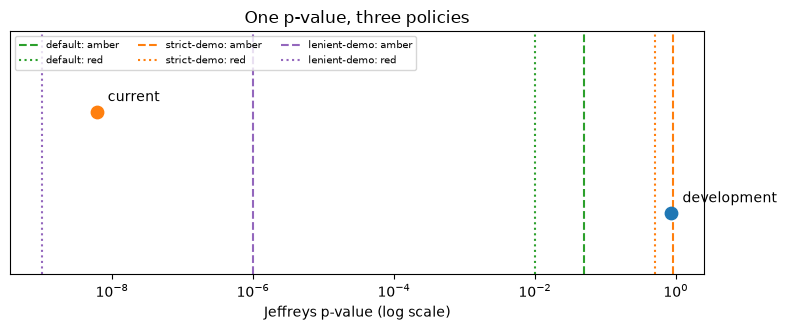

In [8]:
# Draw the two p-values against the cut points of the three policies
fig, ax = plt.subplots(figsize=(8, 3.4))
p_values = {name: jeffreys_under(policy, name).p_value for name in samples}
for row, (name, p_value) in enumerate(p_values.items()):
    ax.scatter([p_value], [row], s=80, zorder=3)
    ax.annotate(name, (p_value, row), textcoords="offset points", xytext=(8, 8))

KINDS = ("amber", "red")
styles = (("default", policy, "tab:green"), ("strict-demo", strict, "tab:orange"), ("lenient-demo", lenient, "tab:purple"))
for label, in_use, color in styles:
    cut = in_use.threshold("pd.jeffreys")
    ax.axvline(cut.amber, color=color, linestyle="--", label=f"{label}: {KINDS[0]}")
    ax.axvline(cut.red, color=color, linestyle=":", label=f"{label}: {KINDS[1]}")
ax.set_xscale("log")
ax.set_yticks([])
ax.set_ylim(-0.6, 1.8)
ax.set_xlabel("Jeffreys p-value (log scale)")
ax.set_title("One p-value, three policies")
ax.legend(fontsize=7, ncol=3, loc="upper left")
fig.tight_layout()
plt.show()

## Results

- **Under the default policy the truth is found.** The development sample, calibrated by construction, is green (p = 0.86). The current sample, with 207 defaults where its PDs expect about 138, is red (p about 6e-9).
- **The colour is a reading, not a property.** The strict policy turns the calibrated development sample amber without any change in the data or the p-value, and the lenient one turns the red current sample amber. A light is meaningful only together with the policy that produced it, and the `TestResult` carries that label for this reason.
- **Missing thresholds are visible.** A test with no threshold in the policy, like the AUC, returns `not_evaluated`. It is never silently green.

This is the wording rule of the whole product: a Contraste light says "under policy `riskvalidation-default 2026.10.1`, the p-value is below 0.01"; it never says that a model is compliant or non-compliant. For the credit tests of this topic, the supervisory sources the engine cites (ECB 2019; BCBS Working Paper 14, 2005) set no such thresholds, and the policy's description says so. What this notebook does not do is choose a policy for you: that is the job of the institution's model risk function.

**The exception: zones a regulation itself defines.** Where the regulatory text sets the zones, the engine computes the zone of that text and names its source instead of reading a policy. `market.basel_traffic_light` assigns green, amber or red from the number of exceptions of a value-at-risk model over 250 days, the backtesting traffic light of the Basel framework (MAR32.9, Table 1: amber where the cumulative binomial probability first reaches 95%, red at 99.99%), and the interest-rate-risk outlier test of the engine compares a measure with 15% of Tier 1 capital (SRP31.82 to SRP31.83). Topics 07 and 09 of this notebook set show those tests. Even there the light is the zone of the text for the number computed, never a verdict that an institution complies.

## Summary

- A `Policy` is versioned data that maps a test identifier to a `Threshold` of kind `p_value`, `upper_bad` or `lower_bad`; the credit tests hold no thresholds.
- The same statistic and p-value give different lights under different policies, and the result records the policy label and cut points.
- A test with no threshold is `not_evaluated`, never green.
- For the credit tests, thresholds are an institution's policy: the sources the engine cites for them set none. Where a regulation defines zones (MAR32.9, SRP31), the engine computes the zone of the text and names its source.

**What to try next.** Add a threshold for `disc.auc` to a policy of your own (kind `lower_bad`) and rerun the AUC of notebook 02 under it. Then continue with notebook 04, which runs a whole battery under one policy.

## References

- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk: they define the tests and set no pass or fail thresholds. https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- BCBS (2005), Studies on the validation of internal rating systems, Working Paper 14 (revised). https://www.bis.org/publications/studies-validation-internal-rating-systems-revised.pdf
- Brown, L. D., Cai, T. T. and DasGupta, A. (2001), Interval estimation for a binomial proportion, Statistical Science 16(2), the Jeffreys interval behind the test. https://doi.org/10.1214/ss/1009213286
- This repository: `docs/design/SDD.md` (non-goal 1: no light is a compliance verdict) and `docs/guides/02_validate-your-own-model.md`.
- BCBS, Basel Framework, MAR32 (internal models approach: backtesting and the traffic light, MAR32.9). https://www.bis.org/basel_framework/chapter/MAR/32.htm
- BCBS, Basel Framework, SRP31 (interest rate risk in the banking book, outlier test, SRP31.82 to SRP31.83). https://www.bis.org/basel_framework/chapter/SRP/31.htm